In [1]:
import pandas as pd


In [3]:
df = pd.read_csv("/content/train.csv")
df.shape

(1460, 81)

In [5]:
df.isnull().sum().sort_values(ascending=False).head(10)
# boshidan 10 ta null qiymatlarni ko'rish

,0
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageQual,81
GarageFinish,81
GarageType,81


In [7]:
miss = (df.isnull().sum() / len(df) * 100).round(2)
miss[miss > 0].sort_values(ascending = False)
# foizda ko'rish null qiymatlarni

,0
PoolQC,99.52
MiscFeature,96.30
Alley,93.77
Fence,80.75
MasVnrType,59.73
FireplaceQu,47.26
LotFrontage,17.74
GarageType,5.55
GarageYrBlt,5.55
GarageFinish,5.55


<Axes: >

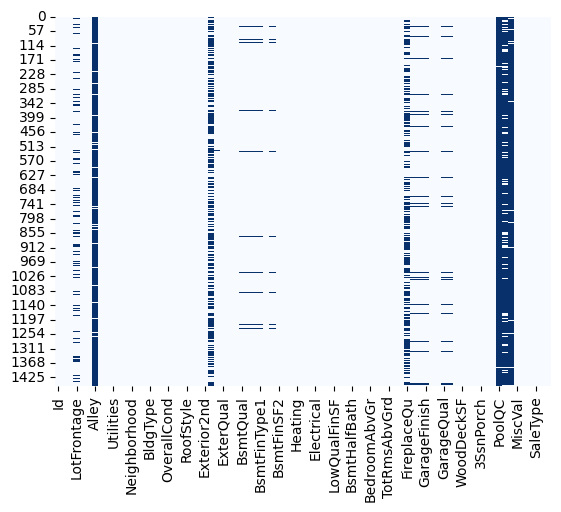

In [10]:
import seaborn as sns
sns.heatmap(df.isnull(), cbar=False, cmap='Blues')
# null qiymatlarni grafikda ko'rish

In [14]:
cat_all = df.select_dtypes(include='object').columns
df[cat_all] = df[cat_all].fillna('None') # kategorik
num = df.select_dtypes(include='number').columns
df[num] = df[num].fillna(df[num].median()) # raqamli
# bu yerda bo'sh qiymatlarni to'ldiramiz

In [ ]:
df['col'].ffil()
# o'zidan oldingi qiymat bilan to'ldiradi.

df['col'].bfill()
# o'zidan keyingi qiymat bilan to'ldiradi.

df['col'].ffill().bfill()
# bu ikkalasini ham ishlatish

In [16]:
df['MSSubClass'].dtypes

dtype('int64')

In [33]:
# Duplicatlarni tekshirish
print(df.duplicated().sum()) # duplicatlar soni
df = df.drop_duplicates() # duplicat bo'lgan qiymatlarni o'chirish

# Barcha type larni ko'rish
print(df.dtypes.value_counts())

# MSSubClass: raqam -> kategorikga o'tkizamiz
df['MSSubClass'] = df['MSSubClass'].astype(str)

0
object     44
int64      34
float64     3
Name: count, dtype: int64


In [34]:
Q1 = df['SalePrice'].quantile(0.25)
Q3 = df['SalePrice'].quantile(0.75)
IQR = Q3 - Q1

outlier = (df['SalePrice'] <= Q1 - 1.5*IQR) | (df['SalePrice'] >= Q3 + 1.5*IQR)
print(outlier.value_counts())

SalePrice
False    1399
True       61
Name: count, dtype: int64


In [36]:
Q1 = df['SalePrice'].quantile(0.25)
Q3 = df['SalePrice'].quantile(0.75)
IQR = Q3 - Q1
# Outlier filter
mask = (df['SalePrice'] >= Q1 - 1.5*IQR) & (df['SalePrice'] <= Q3 + 1.5*IQR)
df_clean = df[mask]
df_clean.shape

(1399, 81)

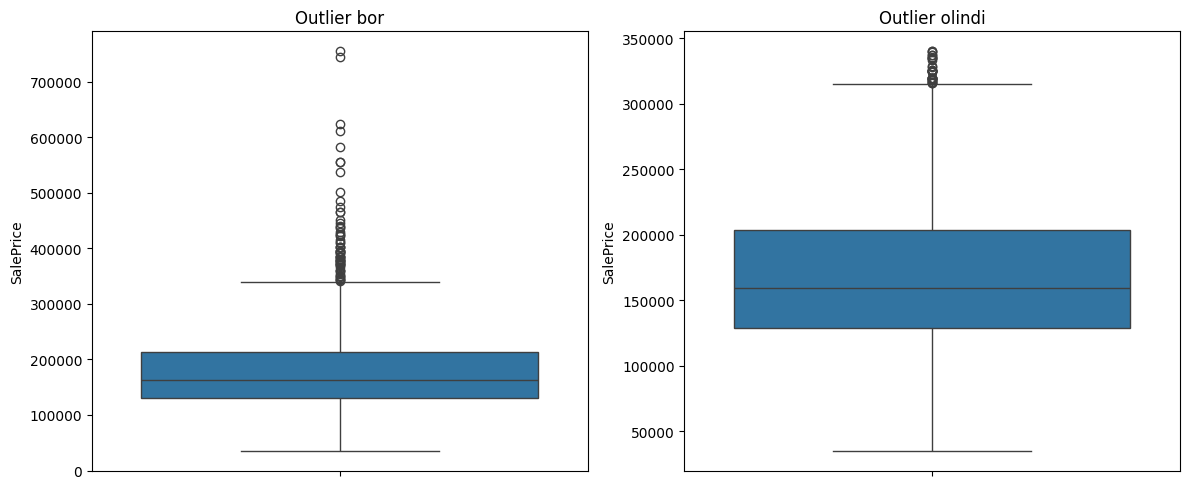

In [37]:
import seaborn as sns
import matplotlib.pyplot as plt

# SalePrice boxplot
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, y='SalePrice', ax=axes[0])
axes[0].set_title('Outlier bor')

sns.boxplot(data=df_clean, y='SalePrice', ax=axes[1])
axes[1].set_title('Outlier olindi')

plt.tight_layout()
plt.show()